# Multiple Linear Regression: Predicting Insurance Charges

This notebook develops a multiple linear regression model to estimate medical insurance charges from customer characteristics. The model is implemented in the project's `MultipleLinearRegression` class and trained with gradient descent.

## Project goals

- Prepare the insurance data for a regression task.
- Train a model and monitor its mean squared error (MSE).
- Evaluate predictions on held-out test data with the R? score.
- Visualize the training loss over time.

## Workflow

1. Import the required libraries and model class.
2. Load the dataset and prepare the target and input features.
3. Standardize features, split the data, and train the model.
4. Evaluate test predictions and inspect the loss curve.
> **Metric note:** R? is a regression score, not classification accuracy. A higher value indicates that the model explains more of the variation in the test targets.


## 1. Import the required libraries


In [1]:
# Import the libraries and project model.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from multipleLinearRegression import MultipleLinearRegression

## 2. Load and prepare the dataset


The dataset contains customer attributes and a `charges` target. This notebook uses the numeric customer attributes as model inputs, converts the `sex` and `smoker` categories to binary values, and excludes `region` from the feature set. The target remains separate so the model can learn to predict it.


In [2]:
# Load the insurance dataset from the project data folder.
data = pd.read_csv(r'data\insurance.csv')
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# Separate the target from the predictor features.
# The target variable is 'charges'.
y_multi = np.asarray(data['charges'].values.tolist())
data.drop(['charges'], axis=1, inplace=True)

In [4]:
# Store the target as a two-dimensional column array.
y_multi = y_multi.reshape(len(y_multi),1) #Changing the shape from ()

In [5]:
# Encode the selected categorical features as numeric values.
data['smoker'] = data['smoker'].map({'yes': 1, 'no': 0})
data['sex'] = data['sex'].map({'male': 1, 'female': 0})

# Exclude 'region' from the predictor features when present.
if 'region' in data.columns:
    data.drop(['region'], axis=1, inplace=True)

# Convert the remaining predictor columns to a NumPy array.
X_multi = np.asarray(data.values.tolist())
data.head


<bound method NDFrame.head of       age  sex     bmi  children  smoker
0      19    0  27.900         0       1
1      18    1  33.770         1       0
2      28    1  33.000         3       0
3      33    1  22.705         0       0
4      32    1  28.880         0       0
...   ...  ...     ...       ...     ...
1333   50    1  30.970         3       0
1334   18    0  31.920         0       0
1335   18    0  36.850         0       0
1336   21    0  25.800         0       0
1337   61    0  29.070         0       1

[1338 rows x 5 columns]>

In [6]:
# Check the dimensions of the feature and target arrays.
print("The shape of the independent fatures are ",X_multi.shape)
print("The shape of the dependent fatures are ",y_multi.shape)

The shape of the independent fatures are  (1338, 5)
The shape of the dependent fatures are  (1338, 1)


## 3. Train and evaluate the model

The feature columns are standardized with z-score scaling, then the data is divided into training and test sets. Gradient descent fits the model using the training set; predictions on the test set are compared with the actual charges using R?.

**Implementation detail:** scaling currently happens before the train/test split, so the scaling statistics include the full dataset. For a stricter evaluation workflow, calculate scaling statistics from the training set only and apply those same statistics to the test set.


In [7]:
# Standardize features, train the model, and evaluate test predictions.

mlr = MultipleLinearRegression() #model initialization
# Apply z-score standardization to each feature.
X_mean = np.mean(X_multi, axis=0)
X_std = np.std(X_multi, axis=0)
X_std[X_std == 0] = 1e-8
X_scaled = (X_multi - X_mean) / X_std

# Split the standardized data into training and test sets.
X_train, X_test, y_train, y_test = mlr.train_test_split(X_scaled, y_multi, test_size=0.2, random_state=42)

# Fit model weights with gradient descent.
mlr.fit_linear_regression(X_train, y_train, learning_rate=0.001, epochs=1000, print_interval=100)

# Generate predictions for the held-out test features.
y_pred_test = mlr.predict(X_test)

# Flatten arrays for the R-squared calculation.
y_test_flat = y_test.flatten()
y_pred_test_flat = y_pred_test.flatten()

# Calculate the coefficient of determination (R-squared).
ss_res = np.sum(np.square(y_test_flat - y_pred_test_flat))
ss_tot = np.sum(np.square(y_test_flat - np.mean(y_test_flat)))
r2_score = 1 - (ss_res / ss_tot)

print(f"\nAkurasi Model (R-Squared): {r2_score * 100:.2f}%")

Epoch     0 | Loss (MSE): 322241666.4166
Epoch   100 | Loss (MSE): 228222968.2582
Epoch   200 | Loss (MSE): 165304541.2111
Epoch   300 | Loss (MSE): 123174622.0560
Epoch   400 | Loss (MSE): 94948408.9914
Epoch   500 | Loss (MSE): 76026551.6633
Epoch   600 | Loss (MSE): 63334732.5957
Epoch   700 | Loss (MSE): 54816831.1452
Epoch   800 | Loss (MSE): 49096916.8693
Epoch   900 | Loss (MSE): 45253707.7795
Epoch   999 | Loss (MSE): 42691080.4442

Akurasi Model (R-Squared): 74.50%


## 4. Review the training loss

The loss plot shows mean squared error across training epochs. A generally decreasing curve indicates that the optimization is reducing training error; it does not by itself measure performance on unseen data. Use the test-set R? above to assess held-out predictions.


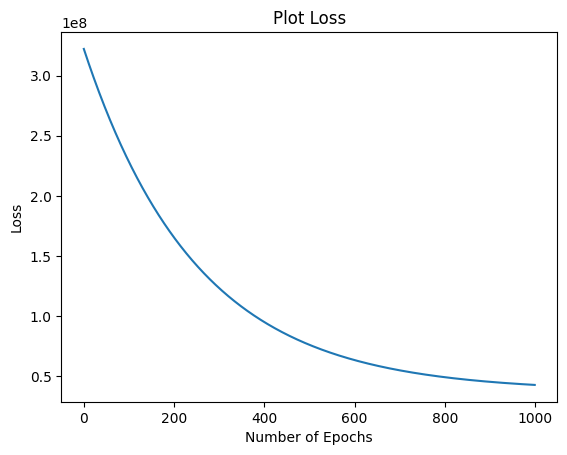

In [8]:
# Plot mean squared error across training epochs.
mlr.plotLoss()